In [10]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
import optuna
import sys
from pathlib import Path
import torch # Torch needs to be installed manually if you want cuda. See installation command on pytorch website

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
SEED = 987
TRACK = "off_market"                     # "off_market" or "list_aware"
VAL_START = pd.Timestamp("2025-06-01")    # sales on or after this date are validation
N_TRIALS = 5                             # optuna trials
N_ESTIMATORS = 2000                      # max boosting rounds per trial
EARLY_STOPPING_ROUNDS = 100
K_FOLDS = 5                              # time series cross validation folds
DEBUG = True                             # print MdAPE and MAPE for every fold

In [12]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

In [ ]:
from baseline_features import off_market_features, list_aware_features, oversample

In [14]:
make_features = off_market_features if TRACK == "off_market" else list_aware_features

train = listings[listings["date_sold"] < VAL_START]
val = listings[listings["date_sold"] >= VAL_START]

X_train = make_features(train)
X_val = make_features(val)

y_train = np.log(train["sold_price"])
y_val = np.log(val["sold_price"])

print(f"train: {len(train):,} sales up to {VAL_START.date()}")
print(f"val:   {len(val):,} sales from {VAL_START.date()}")

train: 127,762 sales up to 2025-06-01
val:   22,238 sales from 2025-06-01


In [15]:
# TODO: Try different losses
def mdape(y_log, pred_log):
    return 100 * np.median(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

loss = mdape

In [16]:
from sklearn.model_selection import TimeSeriesSplit


def cross_val(X, y, params, K=5, debug=False, validation_loss=mdape):
    """Walk-forward K-fold: each fold trains on every row before its validation block.
    X and y must be sorted by time (listings is sorted by date_sold).
    Returns the mean validation loss over the folds."""
    mdape_scores = [] 
    mape_scores = []
    for fold, (train_idx, val_idx) in enumerate(TimeSeriesSplit(n_splits=K).split(X), start=1):
        X_tr, X_va = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]

        model = XGBRegressor(**params, device=DEVICE, n_estimators=N_ESTIMATORS,
                             early_stopping_rounds=EARLY_STOPPING_ROUNDS, random_state=SEED)
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
        pred = model.predict(X_va)
        mdape_scores.append(validation_loss(y_va, pred))

        mape_scores.append(np.mean(100 * np.abs(np.exp(pred) / np.exp(y_va) - 1)))

        if debug:
            error = 100 * np.abs(np.exp(pred) / np.exp(y_va) - 1)
            print(f"fold {fold}: train {len(train_idx):,}  val {len(val_idx):,}  "
                  f"MdAPE {error.median():.2f}%  MAPE {error.mean():.2f}%", flush=True)

    print(f"mean MdAPE {np.mean(mdape_scores):.2f}%  mean MAPE {np.mean(mape_scores):.2f}%", flush=True)
    return np.mean(mdape_scores)

In [17]:
def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, step=0.01),
        "max_depth": trial.suggest_int("max_depth", 3, 13),
        "subsample": trial.suggest_float("subsample", 0.1, 1.0, step=0.1),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.1, 1.0, step=0.1),
        "max_bin": trial.suggest_int("max_bin", 256, 1024),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 0.1, step=0.01),
        "lambda": trial.suggest_float("lambda", 1e-3, 10.0, log=True),
        "alpha": trial.suggest_float("alpha", 1e-3, 10.0, log=True),
        "max_delta_step": trial.suggest_int("max_delta_step", 1, 10),
        "enable_categorical": True,
    }
    score = cross_val(X_train, y_train, params, K=K_FOLDS, debug=DEBUG, validation_loss=loss)
    return score

In [18]:
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name="VAPE GOD VAPE GOD VAPE GOD 420 420 696969!!!!")
study.optimize(objective, n_trials=N_TRIALS)

print("best val MdAPE:", round(study.best_value, 2))
print("best params:", study.best_params)

[I 2026-10-12 20:53:23,238] A new study created in memory with name: VAPE GOD VAPE GOD VAPE GOD 420 420 696969!!!!


fold 1: train 21,297  val 21,293  MdAPE 10.39%  MAPE 12.84%
fold 2: train 42,590  val 21,293  MdAPE 10.75%  MAPE 13.26%
fold 3: train 63,883  val 21,293  MdAPE 9.99%  MAPE 12.45%
fold 4: train 85,176  val 21,293  MdAPE 9.91%  MAPE 12.82%
fold 5: train 106,469  val 21,293  MdAPE 9.78%  MAPE 12.52%
mean MdAPE 10.16%  mean MAPE 12.78%


[I 2026-10-12 20:53:36,397] Trial 0 finished with value: 10.164341278909486 and parameters: {'learning_rate': 0.05, 'max_depth': 7, 'subsample': 0.9, 'colsample_bytree': 0.5, 'max_bin': 908, 'min_child_weight': 10, 'gamma': 0.1, 'lambda': 7.103714746188992, 'alpha': 0.0013187949354214168, 'max_delta_step': 1}. Best is trial 0 with value: 10.164341278909486.


fold 1: train 21,297  val 21,293  MdAPE 10.61%  MAPE 13.08%
fold 2: train 42,590  val 21,293  MdAPE 11.01%  MAPE 13.79%
fold 3: train 63,883  val 21,293  MdAPE 10.78%  MAPE 13.21%
fold 4: train 85,176  val 21,293  MdAPE 10.62%  MAPE 13.66%
fold 5: train 106,469  val 21,293  MdAPE 10.18%  MAPE 12.93%
mean MdAPE 10.64%  mean MAPE 13.33%


[I 2026-10-12 20:53:42,347] Trial 1 finished with value: 10.641681559723674 and parameters: {'learning_rate': 0.09, 'max_depth': 3, 'subsample': 0.8, 'colsample_bytree': 0.8, 'max_bin': 492, 'min_child_weight': 3, 'gamma': 0.08, 'lambda': 4.791227993546376, 'alpha': 0.0058203973119644765, 'max_delta_step': 9}. Best is trial 0 with value: 10.164341278909486.


...

fold 1: train 21,297  val 21,293  MdAPE 11.71%  MAPE 14.55%
fold 2: train 42,590  val 21,293  MdAPE 12.13%  MAPE 15.42%
fold 3: train 63,883  val 21,293  MdAPE 12.11%  MAPE 14.82%
fold 4: train 85,176  val 21,293  MdAPE 11.25%  MAPE 14.56%
fold 5: train 106,469  val 21,293  MdAPE 12.32%  MAPE 15.56%
mean MdAPE 11.90%  mean MAPE 14.98%


[I 2026-10-12 20:54:18,764] Trial 3 finished with value: 11.902545297743043 and parameters: {'learning_rate': 0.09999999999999999, 'max_depth': 7, 'subsample': 0.4, 'colsample_bytree': 0.1, 'max_bin': 710, 'min_child_weight': 6, 'gamma': 0.05, 'lambda': 0.007810199652857199, 'alpha': 0.06821146368694334, 'max_delta_step': 3}. Best is trial 0 with value: 10.164341278909486.


fold 1: train 21,297  val 21,293  MdAPE 10.45%  MAPE 12.99%
fold 2: train 42,590  val 21,293  MdAPE 10.67%  MAPE 13.19%
fold 3: train 63,883  val 21,293  MdAPE 10.11%  MAPE 12.65%
fold 4: train 85,176  val 21,293  MdAPE 9.80%  MAPE 12.80%
fold 5: train 106,469  val 21,293  MdAPE 9.71%  MAPE 12.49%
mean MdAPE 10.15%  mean MAPE 12.82%


[I 2026-10-12 20:54:42,144] Trial 4 finished with value: 10.146677679755486 and parameters: {'learning_rate': 0.03, 'max_depth': 10, 'subsample': 0.8, 'colsample_bytree': 0.9, 'max_bin': 943, 'min_child_weight': 4, 'gamma': 0.08, 'lambda': 0.6719572464324033, 'alpha': 0.012513269016993844, 'max_delta_step': 2}. Best is trial 4 with value: 10.146677679755486.


best val MdAPE: 10.15
best params: {'learning_rate': 0.03, 'max_depth': 10, 'subsample': 0.8, 'colsample_bytree': 0.9, 'max_bin': 943, 'min_child_weight': 4, 'gamma': 0.08, 'lambda': 0.6719572464324033, 'alpha': 0.012513269016993844, 'max_delta_step': 2}


In [19]:
from optuna.importance import get_param_importances

importance = get_param_importances(study)

for param, score in importance.items():
    print(f"{param}: {score:.4f}")

lambda: 0.2653
alpha: 0.2306
max_bin: 0.1849
learning_rate: 0.0644
min_child_weight: 0.0554
max_depth: 0.0553
colsample_bytree: 0.0490
gamma: 0.0380
max_delta_step: 0.0336
subsample: 0.0235


In [20]:
model = XGBRegressor(**study.best_params,
                     enable_categorical=True,
                     device=DEVICE,
                     early_stopping_rounds=EARLY_STOPPING_ROUNDS,
                     n_estimators=N_ESTIMATORS,
                     random_state=SEED)
model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

predicted = np.exp(model.predict(X_val))
error = 100 * np.abs(predicted / val["sold_price"] - 1)
print(f"{TRACK}  MdAPE {error.median():.2f}%  MAPE {error.mean():.2f}%")

off_market  MdAPE 10.20%  MAPE 13.18%


In [21]:
feature_importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
display(feature_importances)

lot_front       0.479002
washrooms       0.190494
square_feet     0.119194
lot_depth       0.063840
community       0.051240
house_type      0.031111
municipality    0.013072
parking         0.011720
day             0.006859
bedrooms        0.006263
month           0.006026
year            0.005891
longitude       0.005652
latitude        0.005541
house_style     0.004095
dtype: float32

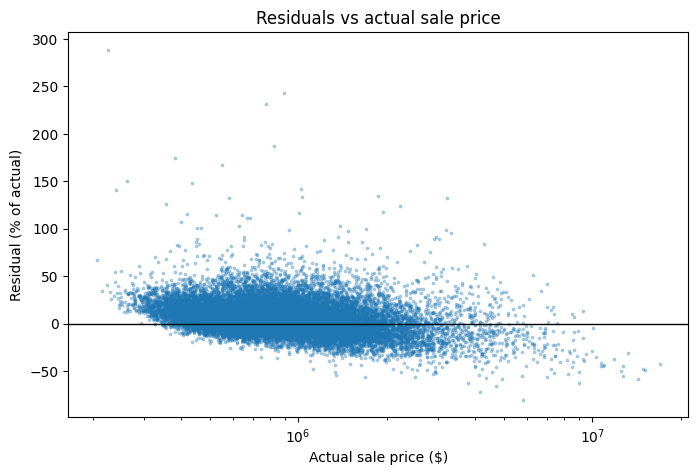

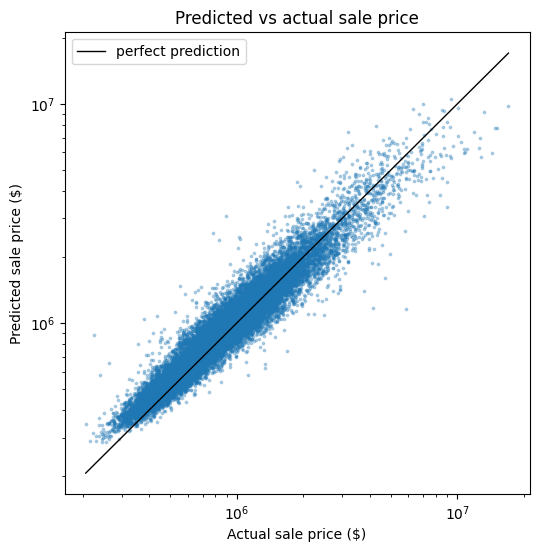

In [22]:
import diagnostics

actual = val["sold_price"]

diagnostics.plot_residuals_vs_actual(actual, predicted)
diagnostics.plot_predicted_vs_actual(actual, predicted)

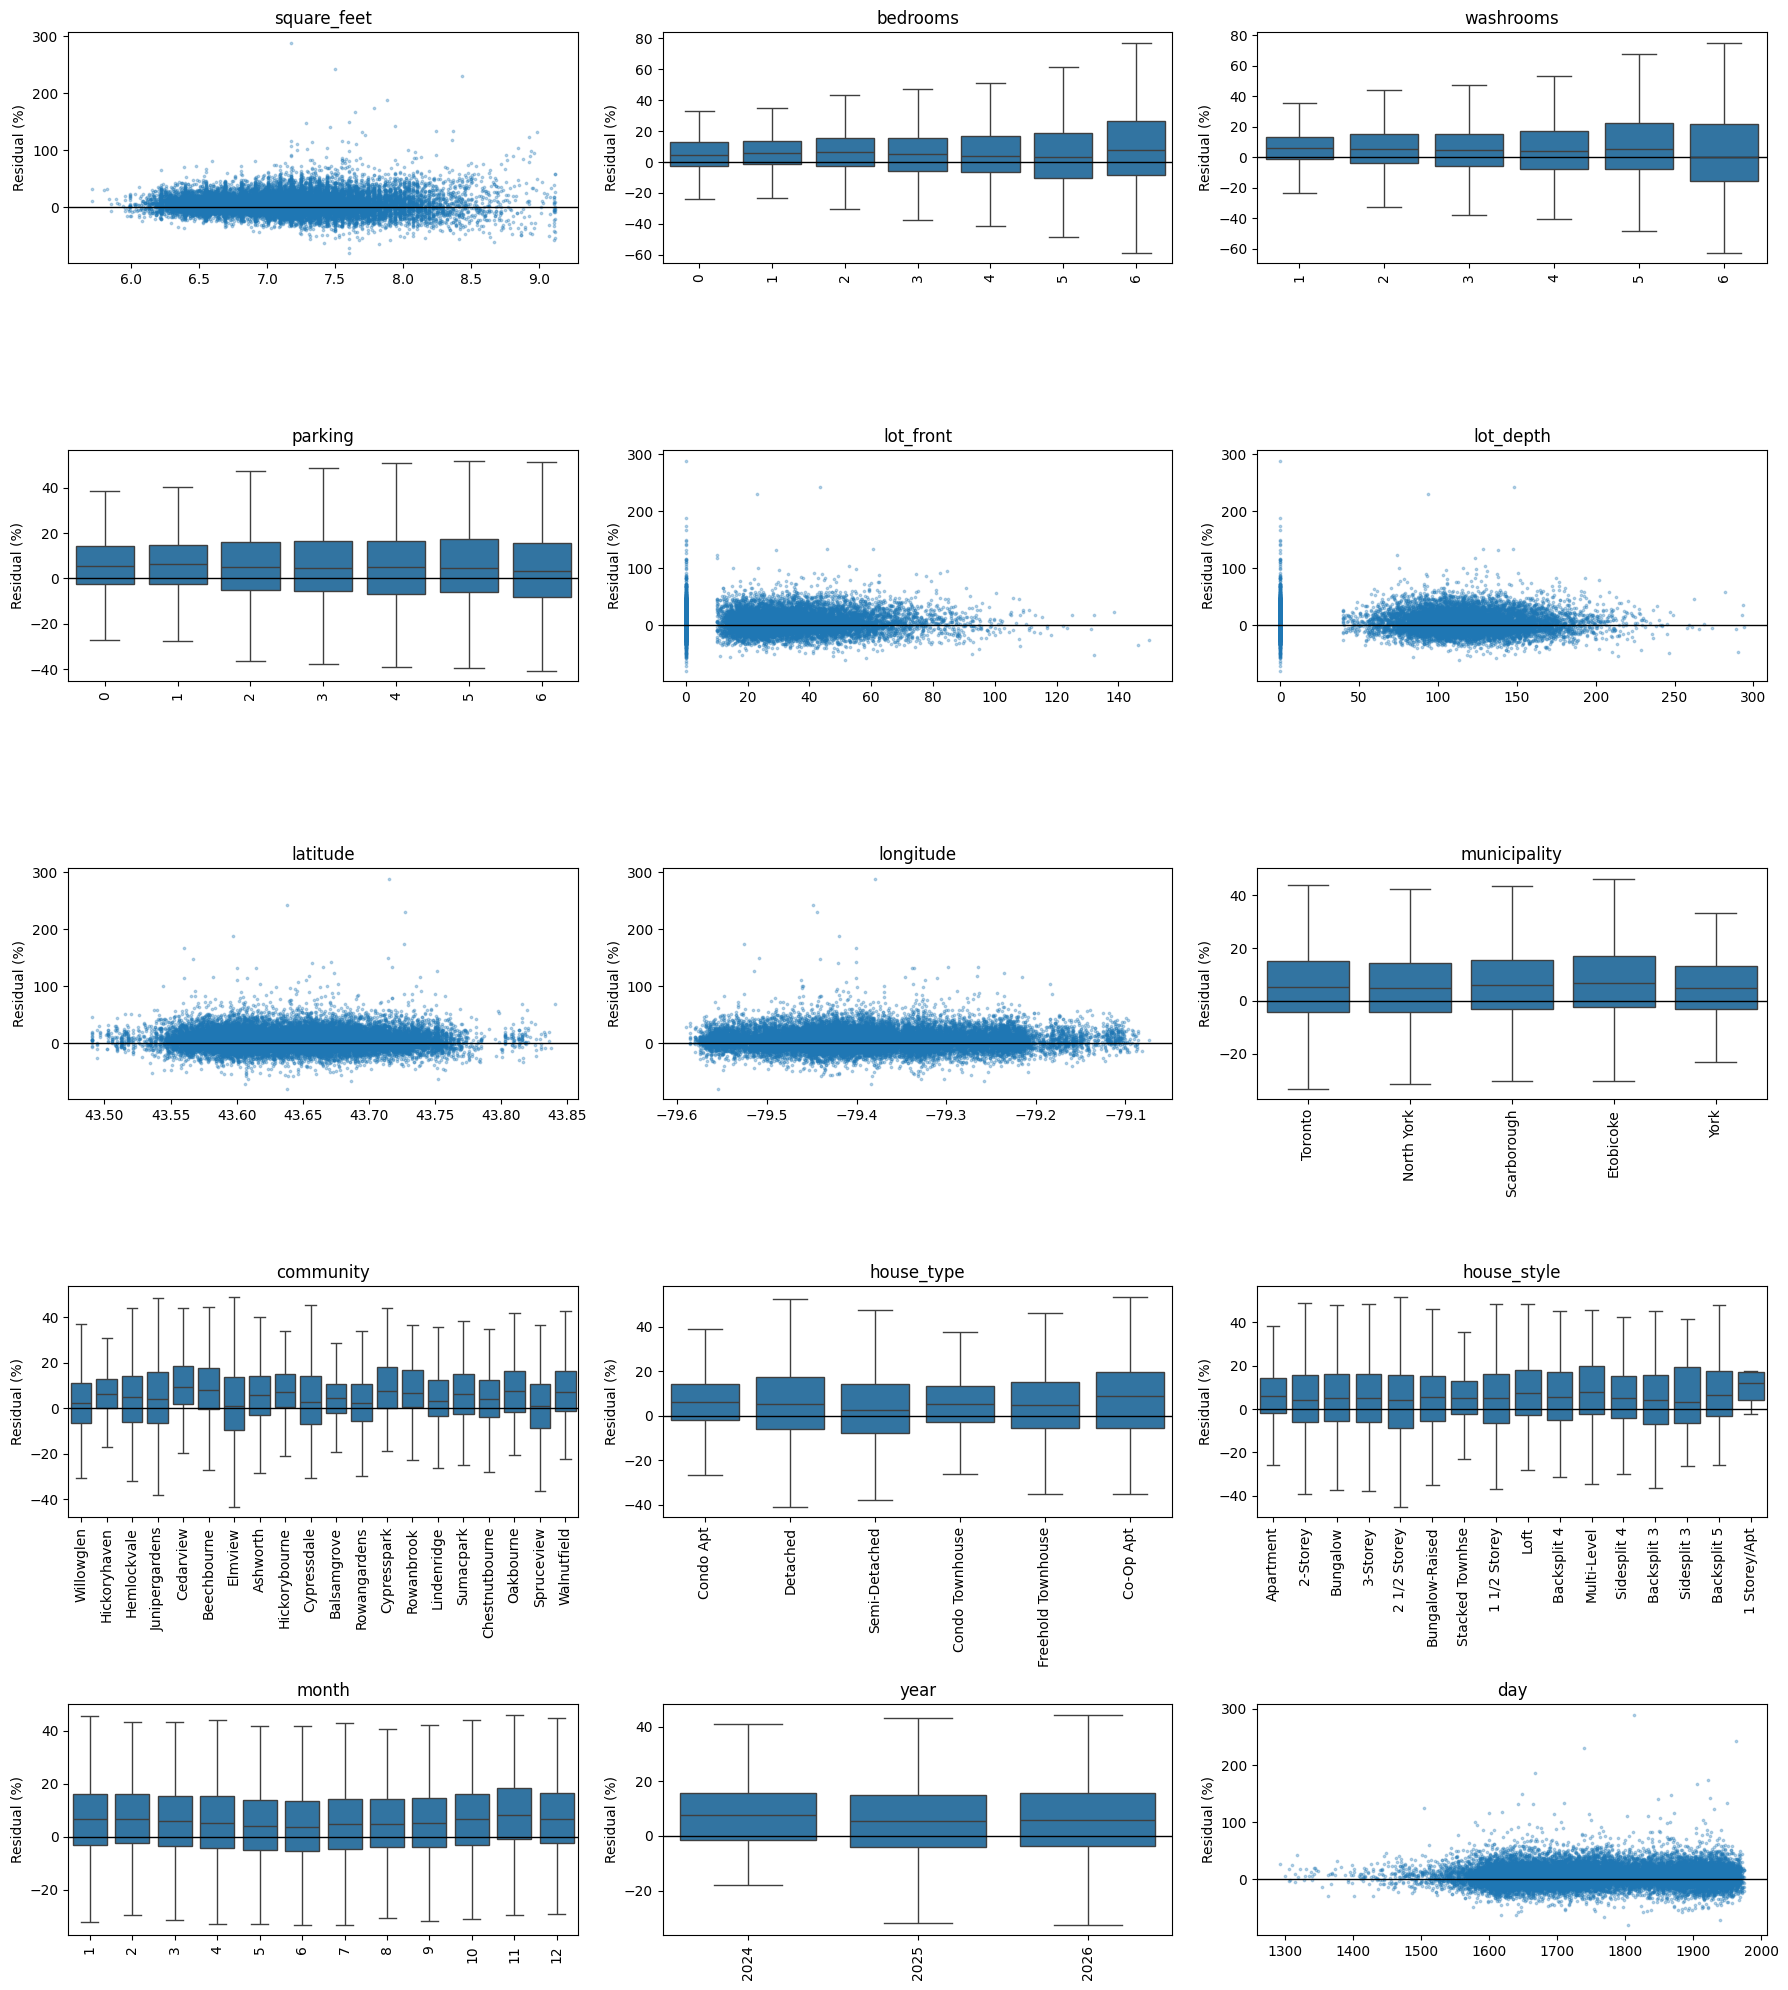

In [23]:
diagnostics.plot_residuals_by_feature(X_val, actual, predicted)

In [24]:
display(diagnostics.worst_predictions(val, actual, predicted, n=20))

,ml_num,sold_price,list_price,date_listed,date_sold,days_on_market,house_type_name,house_style,bedrooms,washrooms,...,municipality,community,latitude,longitude,external_avm_estimate,external_avm_estimate_date,remarks,actual_price,predicted_price,error_pct
143821,SYN-0138680,226200.0,249900.0,2025-12-19,2026-03-03,74,Condo Apt,Apartment,2,2,...,North York,Tamarackmills,43.714859,-79.379343,236200.0,2026-12-30,Imagine coming home to Tamarackmills after a l...,226200.0,879416.0,288.8
149497,SYN-0031235,892200.0,883100.0,2026-05-18,2026-05-24,6,Detached,2-Storey,3,2,...,Toronto,Juniperheights,43.637852,-79.448327,819700.0,2027-01-31,"A 3-bedroom, 2-bathroom detached home on a gen...",892200.0,3063881.0,243.4
137167,SYN-0054443,777400.0,757700.0,2025-10-07,2025-10-19,12,Semi-Detached,3-Storey,4,6,...,North York,Maplemills,43.727537,-79.443527,777900.0,2026-04-26,"A 4-bedroom, 6-bathroom semi on Elm Boulevard ...",777400.0,2574811.0,231.2
136261,SYN-0084563,830600.0,934700.0,2025-07-27,2025-10-07,72,Condo Apt,Apartment,4,5,...,North York,Hawthornbourne,43.597357,-79.419595,855100.0,2025-10-26,Picture hosting dinner parties in a spacious 4...,830600.0,2387353.0,187.4
149681,SYN-0020314,380100.0,438000.0,2026-04-06,2026-05-27,51,Condo Apt,Apartment,3,2,...,Etobicoke,Cypressglen,43.726367,-79.525890,808300.0,2026-05-06,Picture weekend mornings at the eat-in kitchen...,380100.0,1042975.0,174.4
145125,SYN-0101164,551900.0,548100.0,2026-03-21,2026-03-25,4,Condo Apt,Apartment,3,3,...,Toronto,Beechglen,43.560499,-79.400241,541000.0,2026-12-27,Discover this spacious three-bedroom condo wit...,551900.0,1471962.0,166.7
131144,SYN-0081351,262700.0,284700.0,2025-07-08,2025-07-18,10,Co-Op Apt,Apartment,3,2,...,Etobicoke,Cypressglen,43.714112,-79.509083,274000.0,2026-05-24,Oak Gardens co-op with a kitchen redone using ...,262700.0,657197.0,150.2
149155,SYN-0087681,434400.0,447000.0,2026-02-11,2026-05-20,98,Co-Op Apt,Apartment,2,3,...,Toronto,Hemlockvale,43.566612,-79.441261,409200.0,2027-01-09,Imagine a quiet morning walk to nearby parks a...,434400.0,1079047.0,148.4
146290,SYN-0100189,1022900.0,1089600.0,2026-04-09,2026-04-12,3,Condo Apt,2-Storey,3,5,...,Etobicoke,Cedarheights,43.671127,-79.400462,1080500.0,2026-08-19,Imagine yourself in Cedarheights! This spaciou...,1022900.0,2474068.0,141.9
144832,SYN-0061334,240300.0,266100.0,2026-01-23,2026-03-20,56,Condo Apt,Apartment,3,3,...,Toronto,Sumacwood,43.657023,-79.420527,644700.0,2026-03-19,"Picture yourself on a winter morning, coffee i...",240300.0,577815.0,140.5
